# AI feature 2: Virality predictor

**Business question.** On the morning a video first appears on the trending list, can we tell whether it will become a long-runner, and how many days it will stay?

**Why not "will it trend?"** Every video in the data trended, so there are no examples of videos that did not. The question was reframed to one the data can answer: staying power once trending.

**Targets.** `long_runner`: the run reaches the length that only the top quarter of training runs reach in that country (7 days in the US and UK, 5 in India). `days_trending`: days on the list.

**Features** are only what is known on the first trending day: first-day views, likes and comments, days from upload to trending, upload hour and weekday, title features and sentiment, tag count, category, country, India's data period, and the channel's record from runs that had already ended. Built in `streampulse/virality.py`; the no-leakage rule is tested in `tests/test_virality.py`.

**Split by time.** Train: Aug 2020 to Dec 2022. Validation (early stopping only): Jan to Jun 2023. Test: Jul 2023 to Apr 2024. Models trained in `streampulse/virality_model.py` and logged to MLflow.

In [1]:
import json
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# shap imports a progress-bar library that warns when notebook widgets are not installed; nothing here uses it.
warnings.filterwarnings("ignore", message="IProgress not found")
import shap
from sklearn.metrics import mean_absolute_error, roc_auc_score

from streampulse.charts import COUNTRIES, COUNTRY_COLORS, COUNTRY_NAMES, SINGLE_SERIES_COLOR, apply_chart_style
from streampulse.virality import FEATURES_PATH
from streampulse.virality_model import (
    CATEGORIES_PATH, CLASSIFIER_PATH, FEATURE_COLUMNS, REGRESSOR_PATH, RESULTS_PATH, baseline_scores, feature_matrix,
)

apply_chart_style()
features = pd.read_parquet(FEATURES_PATH)
train_rows = features[features["split"] == "train"]
categories = json.loads(CATEGORIES_PATH.read_text(encoding="utf-8"))
classifier = lgb.Booster(model_file=str(CLASSIFIER_PATH))
regressor = lgb.Booster(model_file=str(REGRESSOR_PATH))

scored = features[features["split"] != "train"].copy()
scored_matrix = feature_matrix(scored, categories)
baseline_long_run, baseline_days = baseline_scores(train_rows, scored)
scored = scored.assign(
    long_run_probability=classifier.predict(scored_matrix),
    predicted_days=regressor.predict(scored_matrix),
    baseline_long_run=baseline_long_run,
    baseline_days=baseline_days,
)
features.groupby("split").agg(runs=("video_id", "size"), long_runner_rate=("long_runner", "mean")).round(3)

,runs,long_runner_rate
split,,
test,34609,0.282
train,114560,0.210
validation,23267,0.224


## 1. Results against the baseline

The baseline uses channel history alone: the channel's past long-run rate and average days, or the country average for channels with no finished runs yet. Phase 3 showed the channel matters most, so this is the bar to beat.

In [2]:
pd.read_csv(RESULTS_PATH).round(3)

,task,model,split,roc_auc,pr_auc,brier,actual_positive_rate,mean_predicted_probability,mae_days,rmse_days
0,classifier,baseline,validation,0.683,0.376,0.168,0.224,0.201,NaN,NaN
1,classifier,lightgbm,validation,0.804,0.568,0.135,0.224,0.202,NaN,NaN
2,regressor,baseline,validation,NaN,NaN,NaN,NaN,NaN,1.073,1.473
3,regressor,lightgbm,validation,NaN,NaN,NaN,NaN,NaN,0.914,1.273
4,classifier,baseline,test,0.698,0.465,0.191,0.282,0.212,NaN,NaN
5,classifier,lightgbm,test,0.790,0.605,0.165,0.282,0.207,NaN,NaN
6,regressor,baseline,test,NaN,NaN,NaN,NaN,NaN,1.213,1.752
7,regressor,lightgbm,test,NaN,NaN,NaN,NaN,NaN,1.078,1.608


In [3]:
country_rows = []
for country, rows in scored[scored["split"] == "test"].groupby("country"):
    country_rows.append({
        "country": country,
        "runs": len(rows),
        "actual_long_runner_rate": rows["long_runner"].mean(),
        "mean_predicted_probability": rows["long_run_probability"].mean(),
        "auc_lightgbm": roc_auc_score(rows["long_runner"], rows["long_run_probability"]),
        "auc_baseline": roc_auc_score(rows["long_runner"], rows["baseline_long_run"]),
        "mae_days_lightgbm": mean_absolute_error(rows["days_trending"], rows["predicted_days"]),
        "mae_days_baseline": mean_absolute_error(rows["days_trending"], rows["baseline_days"]),
    })
pd.DataFrame(country_rows).set_index("country").loc[COUNTRIES].round(3)

,runs,actual_long_runner_rate,mean_predicted_probability,auc_lightgbm,auc_baseline,mae_days_lightgbm,mae_days_baseline
country,,,,,,,
IN,16866,0.170,0.187,0.883,0.781,0.878,1.060
US,8736,0.420,0.170,0.724,0.639,1.385,1.391
GB,9007,0.358,0.280,0.738,0.620,1.154,1.326


## 2. Is it useful? Long-runner rate by predicted score

Test videos are sorted into ten equal groups by the model's score within each country. If the model ranks well, the highest-scored groups should contain far more long-runners than the country average.

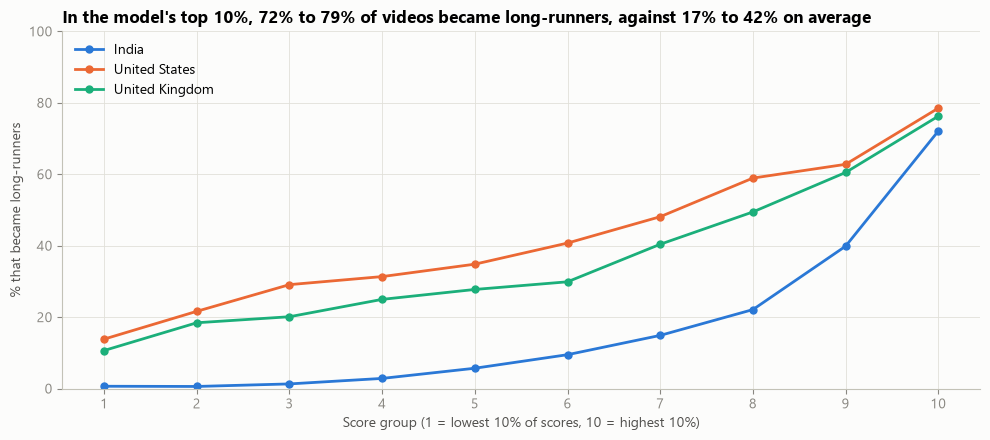

score_decile,1,2,3,4,5,6,7,8,9,10
country,,,,,,,,,,
IN,0.7,0.6,1.3,2.8,5.7,9.5,14.9,22.1,39.9,72.1
US,13.8,21.6,29.1,31.4,34.8,40.7,48.1,58.9,62.8,78.5
GB,10.7,18.4,20.1,25.0,27.7,29.9,40.4,49.4,60.5,76.2


In [4]:
test_scored = scored[scored["split"] == "test"].copy()
test_scored["score_decile"] = test_scored.groupby("country")["long_run_probability"].transform(
    lambda scores: pd.qcut(scores.rank(method="first"), 10, labels=range(1, 11)).astype(int)
)
decile_rates = test_scored.groupby(["score_decile", "country"])["long_runner"].mean().unstack("country")[COUNTRIES]

fig, ax = plt.subplots(figsize=(10, 4.5))
for country in COUNTRIES:
    ax.plot(decile_rates.index, 100 * decile_rates[country], marker="o", markersize=5,
            color=COUNTRY_COLORS[country], label=COUNTRY_NAMES[country])
ax.set_xticks(range(1, 11))
ax.set_ylim(0, 100)
ax.set_xlabel("Score group (1 = lowest 10% of scores, 10 = highest 10%)")
ax.set_ylabel("% that became long-runners")
ax.set_title("In the model's top 10%, 72% to 79% of videos became long-runners, against 17% to 42% on average")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

(100 * decile_rates).round(1).T

## 3. Drift: the model is too cautious for the US and UK in 2023

Monthly share of runs that became long-runners, against the model's average predicted probability, for the validation and test periods.

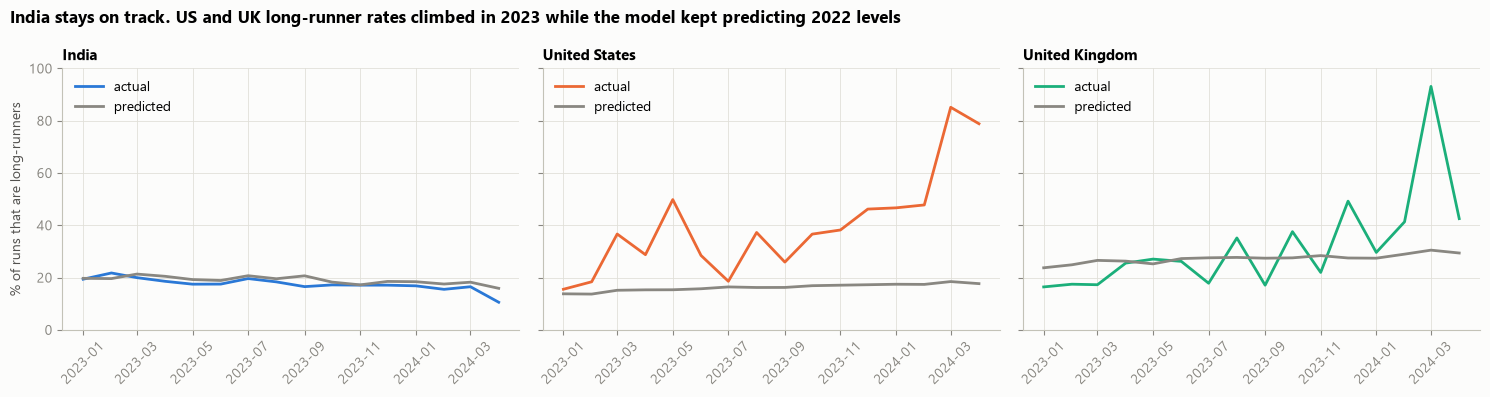

In [5]:
monthly = (
    scored.assign(month=pd.to_datetime(scored["first_trending_date"]).dt.to_period("M").dt.to_timestamp())
    .groupby(["country", "month"])
    .agg(actual=("long_runner", "mean"), predicted=("long_run_probability", "mean"))
    .reset_index()
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, country in zip(axes, COUNTRIES):
    rows = monthly[monthly["country"] == country]
    ax.plot(rows["month"], 100 * rows["actual"], color=COUNTRY_COLORS[country], label="actual")
    ax.plot(rows["month"], 100 * rows["predicted"], color="#898781", label="predicted")
    ax.set_title(COUNTRY_NAMES[country], fontsize=11)
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=45)
    ax.legend(loc="upper left")
axes[0].set_ylabel("% of runs that are long-runners")
fig.suptitle("India stays on track. US and UK long-runner rates climbed in 2023 while the model kept predicting 2022 levels",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## 4. What drives the predictions (SHAP)

SHAP splits each prediction into a contribution from every feature, on the model's log-odds scale for the classifier. LightGBM computes exact SHAP values for its own trees; section 4 checks they match the `shap` library's values. Explanations use 5,000 test runs.

In [6]:
explained = scored[scored["split"] == "test"].sample(5000, random_state=0)
explained_matrix = feature_matrix(explained, categories)
classifier_contributions = classifier.predict(explained_matrix, pred_contrib=True)
shap_library_values = shap.TreeExplainer(classifier)(explained_matrix).values
print("largest difference between LightGBM and shap library values:",
      float(np.abs(classifier_contributions[:, :-1] - shap_library_values).max()))
print("largest gap between summed contributions and the model's raw score:",
      float(np.abs(classifier_contributions.sum(axis=1) - classifier.predict(explained_matrix, raw_score=True)).max()))

classifier_explanation = shap.Explanation(
    values=classifier_contributions[:, :-1],
    base_values=classifier_contributions[:, -1],
    data=explained[FEATURE_COLUMNS].to_numpy(),
    feature_names=FEATURE_COLUMNS,
)

largest difference between LightGBM and shap library values: 0.0
largest gap between summed contributions and the model's raw score: 3.108624468950438e-14


Features grouped by what they describe. The share is each group's part of the total mean absolute SHAP value.

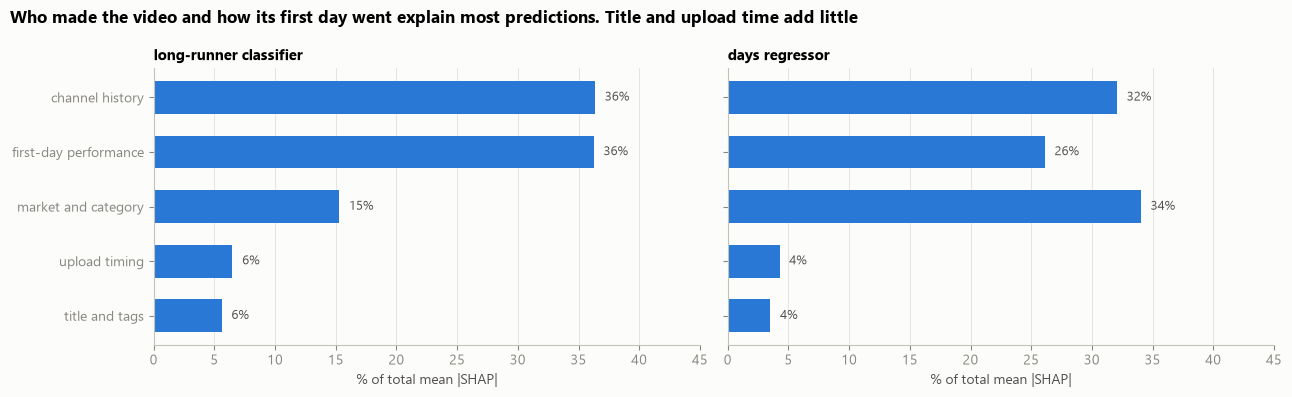

,long-runner classifier,days regressor
channel history,36.4,32.1
first-day performance,36.3,26.1
market and category,15.3,34.0
upload timing,6.5,4.3
title and tags,5.6,3.5


In [7]:
FEATURE_GROUPS = {
    "channel history": [column for column in FEATURE_COLUMNS if column.startswith("channel_prior")],
    "first-day performance": ["log_first_day_views", "first_day_likes_per_1k_views",
                              "first_day_comments_per_1k_views", "days_to_trend"],
    "market and category": ["country", "category", "india_after_list_change"],
    "upload timing": ["upload_hour_local", "upload_weekday_local"],
    "title and tags": [column for column in FEATURE_COLUMNS
                       if column.startswith("has_") or column in ("title_words", "sentiment", "sentiment_label", "tag_count")],
}
regressor_contributions = regressor.predict(explained_matrix, pred_contrib=True)


def group_shares(contributions):
    mean_absolute = pd.Series(np.abs(contributions[:, :-1]).mean(axis=0), index=FEATURE_COLUMNS)
    return 100 * pd.Series({group: mean_absolute[columns].sum() for group, columns in FEATURE_GROUPS.items()}) / mean_absolute.sum()


shares = pd.DataFrame({"long-runner classifier": group_shares(classifier_contributions),
                       "days regressor": group_shares(regressor_contributions)})
group_order = shares["long-runner classifier"].sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, model_name in zip(axes, shares.columns):
    ax.barh(group_order, shares.loc[group_order, model_name], color=SINGLE_SERIES_COLOR, height=0.6)
    for y_position, share in enumerate(shares.loc[group_order, model_name]):
        ax.text(share + 0.8, y_position, f"{share:.0f}%", va="center", fontsize=9, color="#52514e")
    ax.set_title(model_name, fontsize=11)
    ax.set_xlabel("% of total mean |SHAP|")
    ax.set_xlim(0, 45)
    ax.grid(axis="y", visible=False)
fig.suptitle("Who made the video and how its first day went explain most predictions. Title and upload time add little",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

shares.round(1)

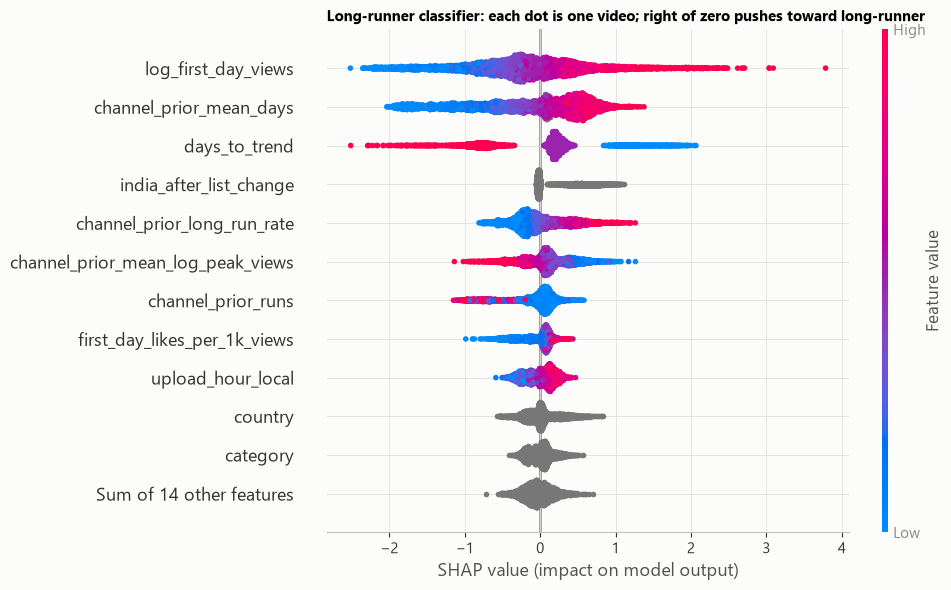

In [8]:
shap.plots.beeswarm(classifier_explanation, max_display=12, show=False, plot_size=(10, 6))
plt.title("Long-runner classifier: each dot is one video; right of zero pushes toward long-runner", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

Colours show the feature's value from low (blue) to high (red). Categorical features (country, category, India's period) have no low or high, so they appear grey.

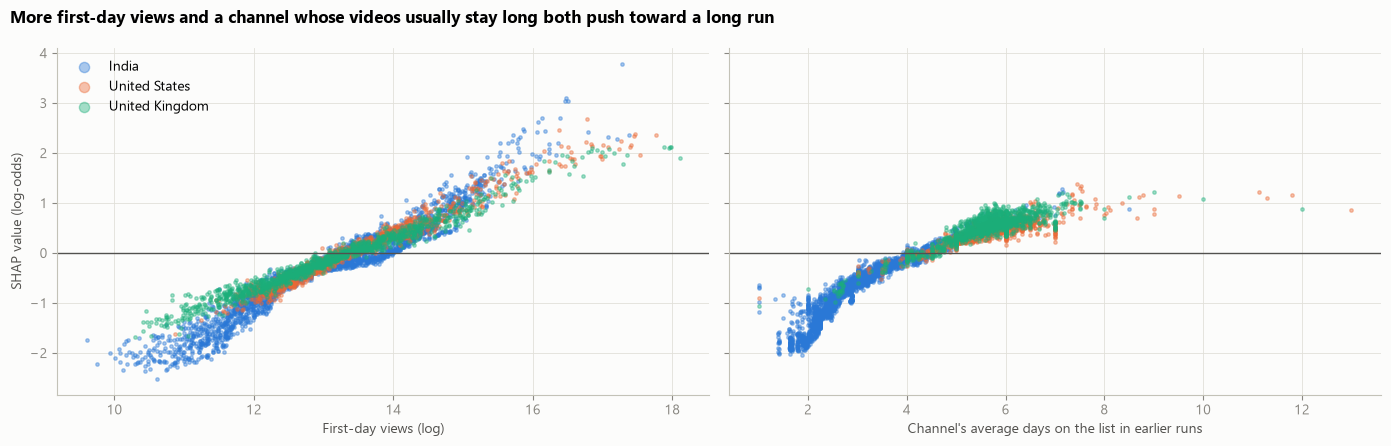

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, column, label in [
    (axes[0], "log_first_day_views", "First-day views (log)"),
    (axes[1], "channel_prior_mean_days", "Channel's average days on the list in earlier runs"),
]:
    column_position = FEATURE_COLUMNS.index(column)
    for country in COUNTRIES:
        in_country = (explained["country"] == country).to_numpy()
        ax.scatter(explained.loc[in_country, column], classifier_contributions[in_country, column_position],
                   s=6, alpha=0.4, color=COUNTRY_COLORS[country], label=COUNTRY_NAMES[country])
    ax.axhline(0, color="#52514e", linewidth=1)
    ax.set_xlabel(label)
axes[0].set_ylabel("SHAP value (log-odds)")
axes[0].legend(markerscale=3)
fig.suptitle("More first-day views and a channel whose videos usually stay long both push toward a long run",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

One test video the model scored highest, explained feature by feature:

Samdhan Zor Ki Hai | the mridul | Pragati | Nitin | IN | Comedy | predicted probability 0.97 | actual days 7


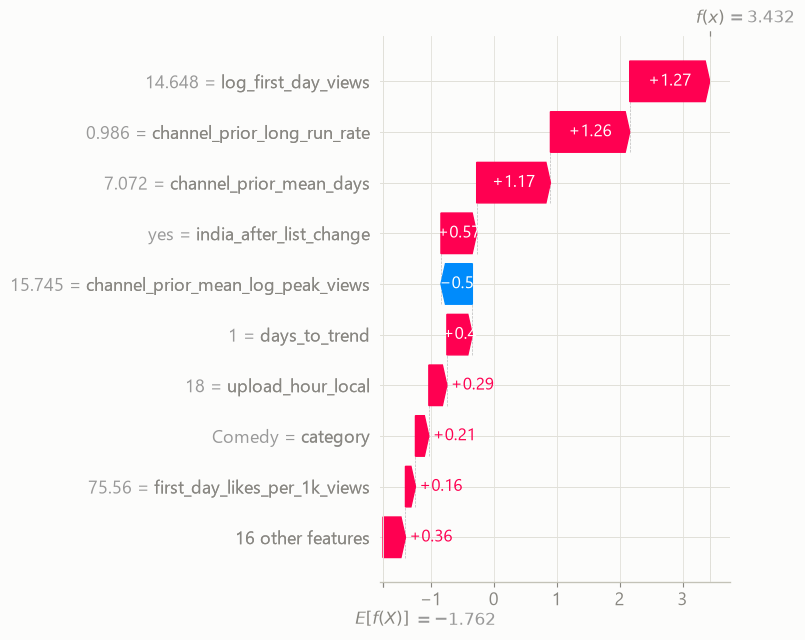

In [10]:
top_position = int(np.argmax(explained["long_run_probability"].to_numpy()))
top_video = explained.iloc[top_position]
print(f"{top_video['title']} | {top_video['country']} | {top_video['category']} | "
      f"predicted probability {top_video['long_run_probability']:.2f} | actual days {top_video['days_trending']}")
shap.plots.waterfall(classifier_explanation[top_position], max_display=10, show=False)
plt.tight_layout()
plt.show()

## Finding

**The model can tell, on a video's first trending day, which videos are likely to stay. It ranks well in every country but under-predicts how many US and UK videos stay long in 2023-2024.**

- **Better than channel history alone.** Test ROC-AUC 0.790 against 0.698 for the baseline; PR-AUC 0.605 against 0.465 (base rate 0.282). Days on the list: mean error 1.08 days against 1.21.
- **Useful for ranking.** In the model's top 10% of scores, 72% (India), 79% (US) and 76% (UK) of videos became long-runners, against country averages of 17%, 42% and 36%. In India, only 0.7% of the bottom 10% did.
- **Strongest in India** (AUC 0.883, mean error 0.88 days, predicted long-runner rate 18.7% against 17.0% actual). Weaker in the US (0.724) and UK (0.738).
- **Drift.** US and UK videos stayed on the list longer in 2023 and 2024. The 7-day bar fixed from training was reached by 42% of US test runs, but the model predicted 17% on average. It still ranks US videos better than the baseline, but its probabilities are too low and its day estimates for the US are no better than the baseline (1.385 against 1.391). Retraining on recent data would be needed before real use.
- **What drives predictions** (share of mean absolute SHAP, classifier): channel history 36%, first-day performance 36%, market and category 15%, upload timing 7%, title and tags 6%. This matches Phase 3: who made the video and how it starts matter far more than its title or upload time.
- **Feature directions:** more first-day views, a channel whose earlier videos stayed long, and reaching the list within a day of upload all push toward a long run. Given those, a channel with higher past peak views pushes slightly toward a shorter run: big channels' videos tend to peak quickly and leave.

**Limitations**

- Only trending videos are in the data, so the model predicts staying power once trending, not the chance of trending.
- The long-runner bar is fixed from 2020-2022 training data and the list changed after that (drift above).
- `days_to_trend` partly reflects when the daily list was captured (analysis 1), not only how fast a video caught on.
- SHAP explains the model, not causes: a feature with a large SHAP value is useful for prediction, which does not mean changing it would change the outcome.